# Well, Oh Well: which wells to check first, which repairs pay

**Research question.** With a limited budget and limited repair crews, which wells should Strathcona check first, and which repairs should it prioritize based on the oil they could recover, what they cost, and how well similar repairs have held up?

This notebook runs the whole analysis track end to end with time-series methods on the three competition files, and then prices the results with Strathcona's public economics.

| Prototype setting | Value |
|---|---|
| Demo date (all decisions use data up to here) | **2026-06-30** |
| Volume unit | **m³ oil** (1 m³ = 6.2898 bbl) |
| Failure prediction window | next **30 days** |
| Repair outcome window | **90 days** after the job |

**Outside sources** (Strathcona news releases, company-wide C$/boe):
- [S1] Q3 2026 results (2026-11-08): https://boereport.com/2026/11/08/strathcona-resources-ltd-reports-third-quarter-2026-financial-and-operating-results-and-announces-quarterly-dividend/
- [S2] Q4 & FY2025 results (2026-03-11): https://boereport.com/2026/03/11/strathcona-resources-ltd-reports-fourth-quarter-and-full-year-2025-financial-and-operating-results-year-end-reserves-announces-quarterly-dividend-and-board-approval-to-commence-normal-course-issuer/

**Assumptions** (labelled wherever used):
- **A1** Company-wide per-boe economics stand in for Lloydminster Conventional heavy oil, because no segment netback is published.
- **A2** Marginal netback = sales net of blending − royalties − energy opex − transport. Non-energy opex is treated as fixed.
- **A3** Job cost is `field_est_total`, and $0 means unknown.
- **A4** Crew-days come from `job_duration_days`.
- **A5** Demo-date decisions use FY2025 economics, the latest annual figures published before the demo date.

In [1]:
# ---- settings: point DATA_DIR at the folder holding the three parquet files ----
import os, sys, subprocess, json
from pathlib import Path
DATA_DIR = Path(os.environ.get("WOW_DATA", "data"))          # e.g. ".../Competition Dataset"
ROOT = Path.cwd()
SRC, WORK, OUT = ROOT / "src", ROOT / "work", ROOT / "outputs"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
assert (DATA_DIR / "daily_production.parquet").exists(), f"Put the parquet files in {DATA_DIR} or set WOW_DATA"
sys.path.insert(0, str(SRC))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
from common import *
import economics as eco
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
BLUE, ORANGE, AQUA, GRAY, INK, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#9a9893", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#ecebe7", "axes.edgecolor": "#d6d5d0",
                     "axes.titlelocation": "left", "axes.titlesize": 12})
def save(fig, name): fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=180); plt.show()

## 0. Run the pipeline (steps 2–5). It takes about 1 minute and rebuilds everything from the raw files

In [2]:
def run(*a): print(subprocess.run([sys.executable, *map(str, a)], cwd=SRC, capture_output=True, text=True).stdout[-1500:])
run("build_panel.py", DATA_DIR, WORK)          # daily baseline + time-series features
run("train_risk.py", WORK)                     # logistic model vs production-drop ranking
run("repair_outcomes.py", DATA_DIR, WORK)      # rod repair oil recovered + repeat failures
run("export_estimates.py", WORK, OUT)          # well_estimates.csv

oil producer wells: 1990 rows: 3353257
suspect zero readings set to missing: 26569
panel rows: 273719 eligible: 255776
daily rows: 3353257



                24.0
100 Production drop (m3/d)     286 932  0.307                 17.0
100    Production drop (%)     290 932  0.311                 13.5
100                 Random     277 932  0.297                 17.0
standardised coefficients:
 log_days_since_rod_job   -0.317
down30                   -0.217
log_age                  -0.159
eff_ratio_na             -0.143
log_rpm_na               -0.139
eff_ratio                -0.127
log_days_since_fail      -0.112
wcut30_na                -0.093
n_jobs_365               -0.029
wcut_chg_na              -0.026
log_gap                  -0.023
cv30_na                  -0.014
wcut_chg                 -0.006
pct_below                -0.003
trend30_na               -0.003
log_age_na                0.000
chg_7v30_na               0.000
torque_ratio_na           0.003
trend30                   0.010
torque_ratio              0.010
cv30                      0.022
chg_7v30                  0.046
wcut30                    0.137
log_rpm       

     0.549
2024        1309.0                133.060              0.881       0.671           0.603
2025        1418.0                132.414              0.886       0.674           0.609
2026         802.0                150.424              0.864       0.657           0.605
                      jobs  repeat_90d
cause                                 
Fatigue                698       0.703
Load / Excess Stress   183       0.689
Corrosion              562       0.674
Erosion                 57       0.509
                                       jobs  repeat_90d
failure_detail                                         
Rods Routine - Broken Sucker Rod Body   463       0.790
Rods Routine - Box                       78       0.731
Rods Routine  - Upset                   103       0.728
Rod - Broken Corod Body                 117       0.632
Rods Routine - Broken Corod body        529       0.612
Rods Routine  - Bottom Pin               81       0.605
Backed Off -Broken Corod Body           

 in last 365 d; Down 100% of last 7 days
2026-06-30 102031004225W300 Stick Rod Repair             1.262        0.6298                24.8                0.754                  1163                                                                      High 30-day failure risk (63%, rank 9); 11 failures in last 365 d
2026-06-30 106120103520W300 Corod Rod Repair             3.588        0.5885               268.3                0.415                    53 High 30-day failure risk (59%, rank 10); Output 100% below own baseline (3.6 m3/d); 5 failures in last 365 d; Down 100% of last 7 days
       oil_lost_per_day  failure_risk  expected_extra_oil  repeat_failure_rate  comparable_job_count
count          1163.000      1163.000            1163.000             1163.000              1163.000
mean              0.550         0.131              29.180                0.559               884.477
std               1.116         0.113              74.621                0.107               650.832
min  

## 1. What the files can support

In [3]:
prod = pd.read_parquet(DATA_DIR / "daily_production.parquet",
       columns=["uwi", "production_date", "well_daily_status", "flow_direction", "hours_on_prod", "oil_produced_m3"])
prod["production_date"] = pd.to_datetime(prod.production_date)
jobs, fails = load_jobs(DATA_DIR), load_failures(DATA_DIR)
pd.DataFrame({
  "rows": [len(prod), len(jobs), len(fails)],
  "wells": [prod.uwi.nunique(), jobs.uwi.nunique(), fails.uwi.nunique()],
  "first date": [prod.production_date.min().date(), jobs.start_date.min().date(), fails.failure_start_date.min().date()],
  "last date": [prod.production_date.max().date(), jobs.start_date.max().date(), fails.failure_start_date.max().date()]},
  index=["daily_production", "well_jobs", "production_failures"])

,rows,wells,first date,last date
daily_production,5075590,2905,2021-01-01,2026-10-27
well_jobs,15610,1903,2021-01-01,2026-10-27
production_failures,2873,825,2021-12-14,2026-10-26


In [4]:
# Zero vs missing: on Producing wells, is zero oil real downtime or a missing reading?
p = prod[(prod.flow_direction == "production") & (prod.well_daily_status == "Producing")]
oil = np.select([p.oil_produced_m3.isna(), p.oil_produced_m3 == 0], ["missing", "zero"], "positive")
hrs = np.select([p.hours_on_prod == 0, p.hours_on_prod < 24], ["0 h on", "partial"], "24 h on")
pd.crosstab(pd.Series(oil, name="oil"), pd.Series(hrs, name="hours"))

hours,0 h on,24 h on,partial
oil,,,
missing,0,85,2
positive,3807,1802249,85952
zero,444844,296744,6847


Zero oil almost always comes with 0 hours on, which is real downtime. Zero oil with 24 hours on and no water is treated as a missing reading. Truly missing oil values are rare, but some wells have whole days missing.

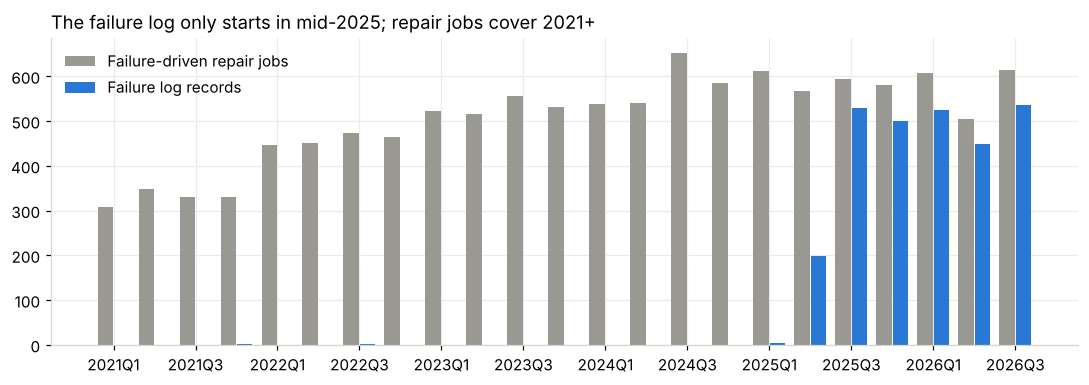

failures with a job within -3..+7 days: 98.2%; same day: 81.0%


In [5]:
# Failure log coverage vs failure-driven repair jobs, by quarter
fq = fails.failure_start_date.dt.to_period("Q").value_counts().sort_index()
jq = jobs[jobs.job_type.isin(FAILURE_JOB_TYPES)].start_date.dt.to_period("Q").value_counts().sort_index()
t = pd.DataFrame({"failure log": fq, "failure-driven repair jobs": jq}).fillna(0).loc["2021Q1":"2026Q3"]
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(t)); ax.bar(x - .2, t["failure-driven repair jobs"], .38, color=GRAY, label="Failure-driven repair jobs")
ax.bar(x + .2, t["failure log"], .38, color=BLUE, label="Failure log records")
ax.set_xticks(x[::2], t.index.astype(str)[::2]); ax.legend(frameon=False)
ax.set_title("The failure log only starts in mid-2025; repair jobs cover 2021+"); save(fig, "01_failure_coverage")
# Linkage: days from failure to nearest job on the same well
m = fails[["uwi", "failure_start_date"]].reset_index().merge(jobs[["uwi", "start_date"]], on="uwi")
m["lag"] = (m.start_date - m.failure_start_date).dt.days
m = m[m.lag.between(-7, 30)].sort_values("lag", key=abs).drop_duplicates("index")
print(f"failures with a job within -3..+7 days: {m.lag.between(-3, 7).sum() / len(fails):.1%}; same day: {(m.lag == 0).sum() / len(fails):.1%}")

## 2. Urgency baseline from each well's own history

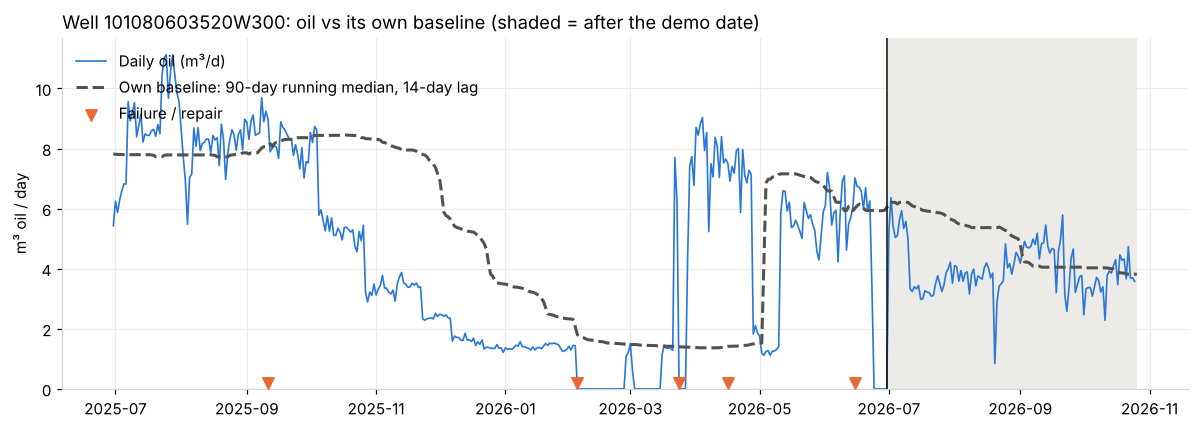

In [6]:
daily = pd.read_parquet(WORK / "oil_daily.parquet")
demo = pd.read_parquet(WORK / "model" / "demo_scores.parquet")
WELL = "101080603520W300"
d = daily[daily.uwi == WELL].set_index("date").sort_index().loc["2025-06-30":"2026-10-27"]
ep = pd.read_parquet(WORK / "episodes.parquet"); e = ep[(ep.uwi == WELL) & ep.date.between(d.index.min(), d.index.max())]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(d.index, d.oil_m3, color=BLUE, lw=1.1, label="Daily oil (m³/d)")
ax.plot(d.index, d.base_oil, color=INK2, lw=2, ls="--", label="Own baseline: 90-day running median, 14-day lag")
ax.axvspan(DEMO_DATE, d.index.max(), color="#ecebe7", lw=0); ax.axvline(DEMO_DATE, color=INK, lw=1)
ax.scatter(e.date, np.full(len(e), 0.2), marker="v", s=55, color=ORANGE, zorder=5, label="Failure / repair")
ax.set_ylabel("m³ oil / day"); ax.set_ylim(bottom=0); ax.legend(frameon=False, loc="upper left")
ax.set_title(f"Well {WELL}: oil vs its own baseline (shaded = after the demo date)"); save(fig, "02_production_chart")

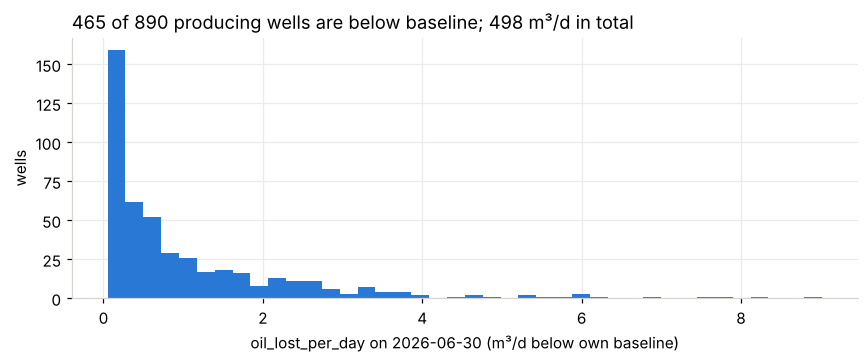

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
v = demo.oil_lost_per_day.fillna(0); ax.hist(v[v > 0.05], bins=40, color=BLUE)
ax.set_xlabel("oil_lost_per_day on 2026-06-30 (m³/d below own baseline)"); ax.set_ylabel("wells")
ax.set_title(f"{(v > 0.05).sum()} of {len(v)} producing wells are below baseline; {v.sum():.0f} m³/d in total"); save(fig, "03_gap_distribution")

## 3. Failure-risk model vs ranking by production drop

In [8]:
met = json.load(open(WORK / "model" / "metrics.json")); cap = pd.read_csv(WORK / "model" / "capacity_eval.csv")
print({k: met[k] for k in ["train_rows", "train_pos", "test_rows", "test_pos", "auc_p_model", "auc_s_gap", "ap_p_model", "ap_s_gap", "ap_s_rand"]})
cap

{'train_rows': 182841, 'train_pos': 25397, 'test_rows': 18279, 'test_pos': 2905, 'auc_p_model': 0.737, 'auc_s_gap': 0.562, 'ap_p_model': 0.36, 'ap_s_gap': 0.194, 'ap_s_rand': 0.155}


,K,method,caught,of,share,median_warning_days
0,25,Logistic model,177,932,0.190,18.0
1,25,Production drop (m3/d),81,932,0.087,18.0
2,25,Production drop (%),89,932,0.095,5.0
3,25,Random,84,932,0.090,13.0
4,50,Logistic model,269,932,0.289,22.0
5,50,Production drop (m3/d),162,932,0.174,16.5
6,50,Production drop (%),177,932,0.190,8.0
7,50,Random,152,932,0.163,15.0
8,100,Logistic model,398,932,0.427,24.0
9,100,Production drop (m3/d),286,932,0.307,17.0


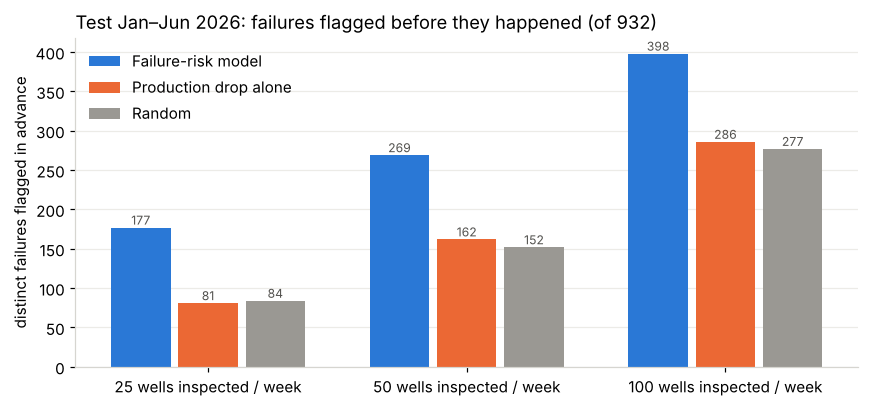

In [9]:
c = cap[cap.method.isin(["Logistic model", "Production drop (m3/d)", "Random"])]
fig, ax = plt.subplots(figsize=(8, 3.8)); Ks = [25, 50, 100]
for k, (mth, col, lab) in enumerate([("Logistic model", BLUE, "Failure-risk model"), ("Production drop (m3/d)", ORANGE, "Production drop alone"), ("Random", GRAY, "Random")]):
    vals = [c[(c.K == K) & (c.method == mth)].caught.iat[0] for K in Ks]
    b = ax.bar(np.arange(3) + (k - 1) * .26, vals, .23, color=col, label=lab); ax.bar_label(b, fontsize=8, color=INK2)
ax.set_xticks(range(3), [f"{K} wells inspected / week" for K in Ks]); ax.legend(frameon=False); ax.grid(axis="x", visible=False)
ax.set_ylabel("distinct failures flagged in advance")
ax.set_title(f"Test Jan–Jun 2026: failures flagged before they happened (of {c.of.iat[0]})"); save(fig, "04_model_vs_baseline")

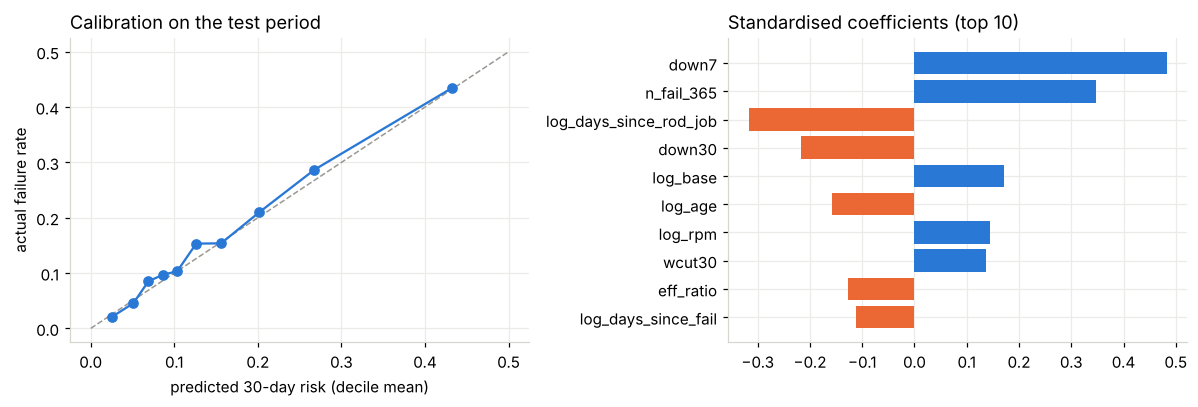

In [10]:
cal = pd.read_csv(WORK / "model" / "calibration.csv"); coef = pd.read_csv(WORK / "model" / "coefficients.csv", index_col=0).iloc[:, 0]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot([0, .5], [0, .5], color=GRAY, ls="--", lw=1); a1.plot(cal.pred, cal.actual, "o-", color=BLUE)
a1.set_xlabel("predicted 30-day risk (decile mean)"); a1.set_ylabel("actual failure rate"); a1.set_title("Calibration on the test period")
top = coef[~coef.index.str.endswith("_na")]; top = top.reindex(top.abs().sort_values().index)[-10:]
a2.barh(top.index, top.values, color=[BLUE if v > 0 else ORANGE for v in top.values]); a2.set_title("Standardised coefficients (top 10)")
save(fig, "05_calibration_coefficients")

## 4. Did rod repairs work?

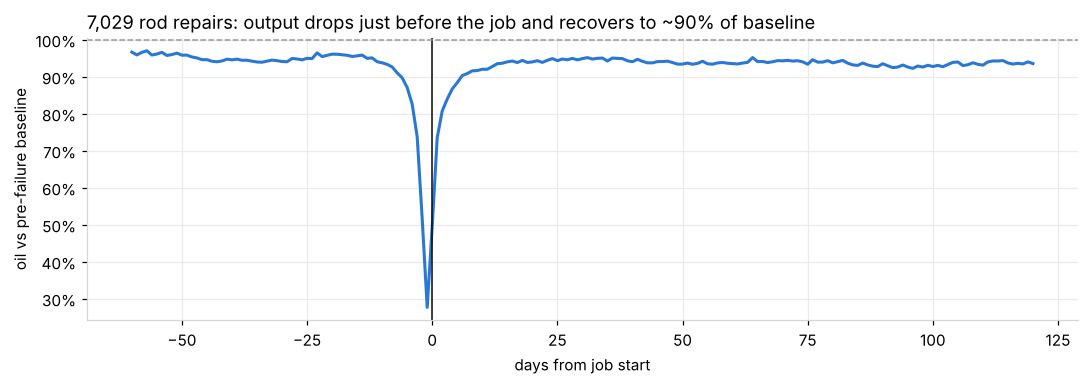

In [11]:
J = pd.read_parquet(WORK / "rod_repair_jobs.parquet")
# Event study: average oil around rod repairs, relative to each well's pre-failure baseline
O = daily.pivot(index="date", columns="uwi", values="oil_m3"); idx = {t: i for i, t in enumerate(O.index)}
rows = []
for r in J[J.pre_base > 0.3].itertuples():
    i = idx.get(r.start_date)
    if i is None or i < 60 or i + 120 >= len(O): continue
    rows.append(O.values[i - 60:i + 121, O.columns.get_loc(r.uwi)] / r.pre_base)
prof = np.nanmean(np.array(rows), axis=0); lag = np.arange(-60, 121)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(lag, prof, color=BLUE, lw=2); ax.axvline(0, color=INK, lw=1); ax.axhline(1, color=GRAY, ls="--", lw=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlabel("days from job start"); ax.set_ylabel("oil vs pre-failure baseline")
ax.set_title(f"{len(rows):,} rod repairs: output drops just before the job and recovers to ~90% of baseline"); save(fig, "06_event_study")

In [12]:
C = J[J.complete_followup & (J.post_coverage >= .8) & (J.pre_base > .3)]
s = C.groupby("job_type").agg(jobs=("uwi", "size"), median_oil_recovered_90d_m3=("oil_recovered_90d", "median"),
     median_restore_ratio=("restore_ratio", "median"), rod_failure_back_within_90d=("repeat_rod_90d", "mean"),
     median_cost_cad=("cost_cad", lambda x: x[x > 0].median()), median_duration_days=("duration_days", "median"))
s.loc["All rod repairs"] = [len(C), C.oil_recovered_90d.median(), C.restore_ratio.median(), C.repeat_rod_90d.mean(), C.cost_cad[C.cost_cad > 0].median(), C.duration_days.median()]
s.round(3)

,jobs,median_oil_recovered_90d_m3,median_restore_ratio,rod_failure_back_within_90d,median_cost_cad,median_duration_days
job_type,,,,,,
Corod Rod Repair,2590.0,145.249,0.892,0.523,6032.13,0.292
Rod Repair,2704.0,144.987,0.905,0.572,4906.80,0.271
Stick Rod Repair,1837.0,121.588,0.872,0.701,2465.00,0.188
All rod repairs,7131.0,139.288,0.892,0.588,4600.00,0.250


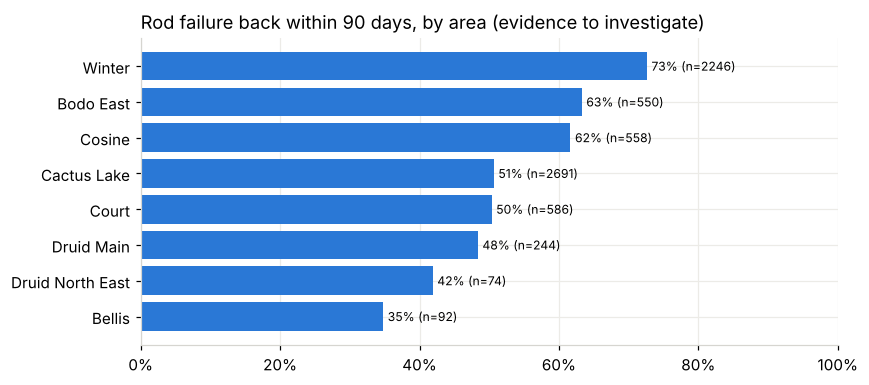

In [13]:
ar = C.groupby("area").agg(jobs=("uwi", "size"), repeat=("repeat_rod_90d", "mean")); ar = ar[ar.jobs >= 50].sort_values("repeat")
fig, ax = plt.subplots(figsize=(8, 3.6)); b = ax.barh(ar.index, ar.repeat, color=BLUE)
ax.bar_label(b, labels=[f"{v:.0%} (n={n})" for v, n in zip(ar.repeat, ar.jobs)], fontsize=8, padding=3)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_xlim(0, 1)
ax.set_title("Rod failure back within 90 days, by area (evidence to investigate)"); save(fig, "07_repeat_by_area")

## 5. Profit: what is a barrel worth, and do repairs pay?

In [14]:
E = eco.ECON.copy(); E.round(2)

,sales,royalties,opex_energy,opex_nonenergy,transport,wcs_cad_bbl,source,marginal_netback_bbl,field_netback_bbl,marginal_netback_m3,field_netback_m3
period,,,,,,,,,,,
FY2024,63.60,9.91,3.71,8.42,8.62,83.53,S2,41.36,32.94,260.15,207.19
FY2025,65.12,8.45,4.28,9.18,8.61,75.06,S2,43.78,34.60,275.37,217.63
Q3 2025,75.74,12.02,3.51,9.79,8.63,75.10,S1,51.58,41.79,324.43,262.85
Q4 2025,66.38,9.24,6.23,8.30,8.80,66.89,S2,42.11,33.81,264.86,212.66
Q2 2026,102.27,21.92,6.03,10.32,9.08,107.95,S1,65.24,54.92,410.35,345.44
Q3 2026,99.47,22.97,5.77,10.56,9.13,100.56,S1,61.60,51.04,387.45,321.03
9M 2026,93.20,19.50,6.32,10.36,9.02,95.91,S1,58.36,48.00,367.07,301.91


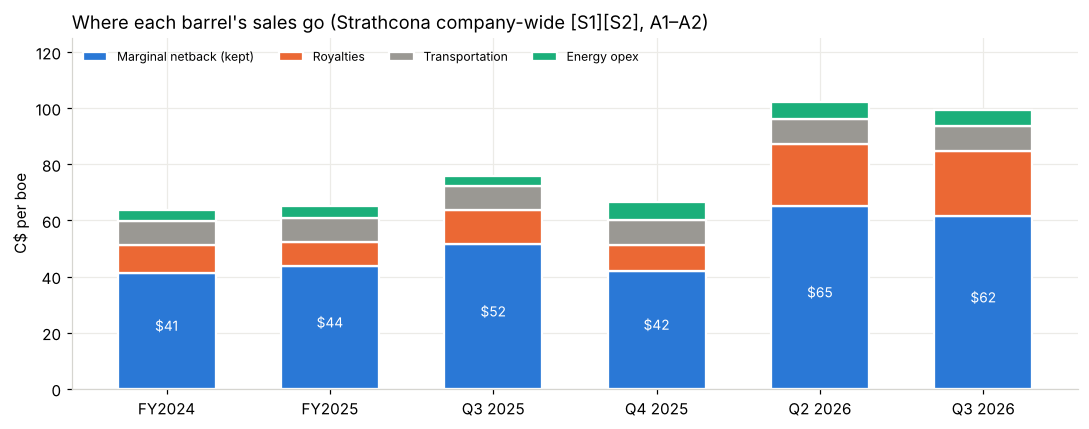

Decision netback (FY2025, A5): 275.4 C$/m3;  Q3 2026: 387.5 C$/m3


In [15]:
order = ["FY2024", "FY2025", "Q3 2025", "Q4 2025", "Q2 2026", "Q3 2026"]
E2 = E.loc[order]; fig, ax = plt.subplots(figsize=(10, 4)); x = np.arange(len(E2))
parts = [("marginal_netback_bbl", BLUE, "Marginal netback (kept)"), ("royalties", ORANGE, "Royalties"),
         ("transport", GRAY, "Transportation"), ("opex_energy", AQUA, "Energy opex")]
bottom = np.zeros(len(E2))
for col, c_, lab in parts:
    ax.bar(x, E2[col], .6, bottom=bottom, color=c_, label=lab, edgecolor="white", lw=1.5); bottom += E2[col].values
for i, v in enumerate(E2.marginal_netback_bbl): ax.text(i, v / 2, f"${v:.0f}", ha="center", color="white", fontsize=9)
ax.set_xticks(x, order); ax.set_ylabel("C$ per boe"); ax.legend(frameon=False, ncol=4, fontsize=8, loc="upper left")
ax.set_title("Where each barrel's sales go (Strathcona company-wide [S1][S2], A1–A2)"); ax.set_ylim(0, 125)
save(fig, "08_netback")
print("Decision netback (FY2025, A5):", round(E.loc["FY2025", "marginal_netback_m3"], 1), "C$/m3;  Q3 2026:", round(E.loc["Q3 2026", "marginal_netback_m3"], 1), "C$/m3")

### Check: does the dataset match what Strathcona reports?

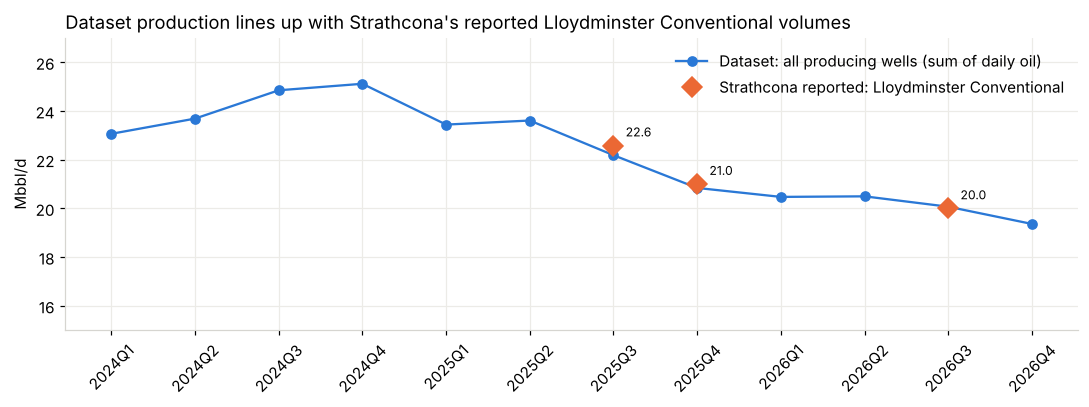

quarter,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3,2026Q4
mbbl_d,23.06,23.69,24.85,25.12,23.44,23.61,22.19,20.84,20.47,20.5,20.07,19.36


In [16]:
dq = eco.dataset_production(DATA_DIR); dq = dq[dq.quarter >= "2024Q1"]
rep = eco.REPORTED_LLOYD
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(dq.quarter, dq.mbbl_d, "o-", color=BLUE, label="Dataset: all producing wells (sum of daily oil)")
ax.plot(rep.quarter, rep.mbbl_d, "D", ms=9, color=ORANGE, label="Strathcona reported: Lloydminster Conventional")
for r in rep.itertuples(): ax.annotate(f"{r.mbbl_d:.1f}", (r.quarter, r.mbbl_d), textcoords="offset points", xytext=(8, 6), fontsize=8)
ax.set_ylabel("Mbbl/d"); ax.set_ylim(15, 27); ax.legend(frameon=False); ax.tick_params(axis="x", rotation=45)
ax.set_title("Dataset production lines up with Strathcona's reported Lloydminster Conventional volumes"); save(fig, "09_dataset_vs_reported")
dq.set_index("quarter").mbbl_d.round(2).to_frame().T

The dataset reads 22.2, then 20.8 Mbbl/d for Q3 → Q4 2025 (−6%). Strathcona reported 21 Mbbl/d in Q4 2025, down 7% quarter over quarter, citing polymer-flood conformance at Cactus Lake and Bodo-Cosine [S2]. For Q3 2026 the dataset reads 20.1 against a reported ~20 [S1]. So the dataset is Strathcona's Lloydminster Conventional business, and the company netbacks are a fair (if approximate, A1) price for its barrels. In the 2026 dataset, Cactus Lake is the largest area at about 6.4 Mbbl/d.

Rod repairs 2023–2026 with known cost & full 90-day follow-up: 4,796
median cost C$4,566 | median value of oil recovered (90 d) C$38,881 | median profit C$33,057 | profitable within 90 d: 81% | median payback 8.3 days


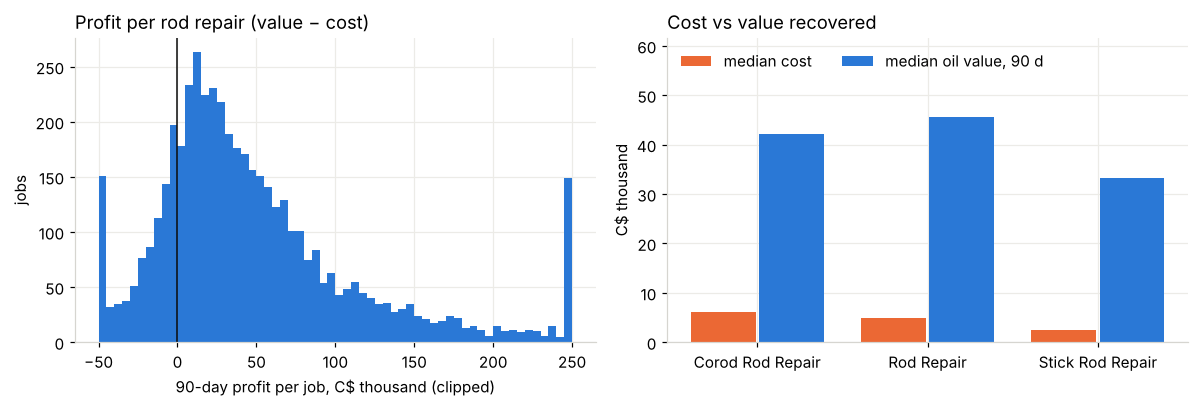

In [17]:
JP = eco.job_profit(WORK); K = JP[JP.cost_known]
print(f"Rod repairs 2023–2026 with known cost & full 90-day follow-up: {len(K):,}")
print(f"median cost C${K.cost_cad.median():,.0f} | median value of oil recovered (90 d) C${K.value_90d_cad.median():,.0f} | "
      f"median profit C${K.profit_90d_cad.median():,.0f} | profitable within 90 d: {(K.profit_90d_cad > 0).mean():.0%} | median payback {K.payback_days.median():.1f} days")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.hist(K.profit_90d_cad.clip(-50e3, 250e3) / 1e3, bins=60, color=BLUE); a1.axvline(0, color=INK, lw=1)
a1.set_xlabel("90-day profit per job, C$ thousand (clipped)"); a1.set_ylabel("jobs"); a1.set_title("Profit per rod repair (value − cost)")
g = K.groupby("job_type").agg(cost=("cost_cad", "median"), value=("value_90d_cad", "median"))
x = np.arange(len(g)); a2.bar(x - .2, g.cost / 1e3, .38, color=ORANGE, label="median cost"); a2.bar(x + .2, g.value / 1e3, .38, color=BLUE, label="median oil value, 90 d")
a2.set_xticks(x, g.index); a2.set_ylabel("C$ thousand"); a2.set_ylim(0, g.value.max() / 1e3 * 1.35); a2.legend(frameon=False, ncol=2, loc="upper left"); a2.set_title("Cost vs value recovered")
save(fig, "10_job_profit")

### Demo date: choose jobs under a budget and crew-day limit

In [18]:
we = eco.candidate_inputs(OUT, JP)
we[["well_id", "job_type", "repair_cost_cad", "crew_days", "cost_source", "crew_days_source"]].to_csv(OUT / "repair_inputs_standin.csv", index=False)
SCEN = {"A: C$50k, 10 crew-days": (50_000, 10), "B: C$150k, 30 crew-days": (150_000, 30)}
rows, picks = [], {}
for name, (B, Cd) in SCEN.items():
    for rule, score in [("Optimiser (net value)", None), ("Rank by failure risk", "failure_risk"), ("Rank by production drop", "oil_lost_per_day")]:
        s = eco.choose_jobs(we, B, Cd, score); picks[(name, rule)] = s
        rows.append(dict(scenario=name, rule=rule, jobs=len(s), cost_cad=s.repair_cost_cad.sum(), crew_days=s.crew_days.sum(),
                         extra_oil_m3=s.expected_extra_oil.sum(), net_value_cad=s.net_value_cad.sum(),
                         expected_failures_in_30d=s.failure_risk.sum()))
R = pd.DataFrame(rows); R.round(1)

,scenario,rule,jobs,cost_cad,crew_days,extra_oil_m3,net_value_cad,expected_failures_in_30d
0,"A: C$50k, 10 crew-days",Optimiser (net value),17,49156.0,4.2,6258.0,1674093.5,4.4
1,"A: C$50k, 10 crew-days",Rank by failure risk,14,48832.0,3.7,1747.6,432400.1,9.0
2,"A: C$50k, 10 crew-days",Rank by production drop,11,48508.0,3.2,5313.8,1414739.5,3.5
3,"B: C$150k, 30 crew-days",Optimiser (net value),46,149294.0,11.8,12825.9,3382541.3,10.8
4,"B: C$150k, 30 crew-days",Rank by failure risk,39,149721.0,10.8,4589.0,1113940.2,20.8
5,"B: C$150k, 30 crew-days",Rank by production drop,33,149073.0,9.9,10297.4,2686495.7,10.0


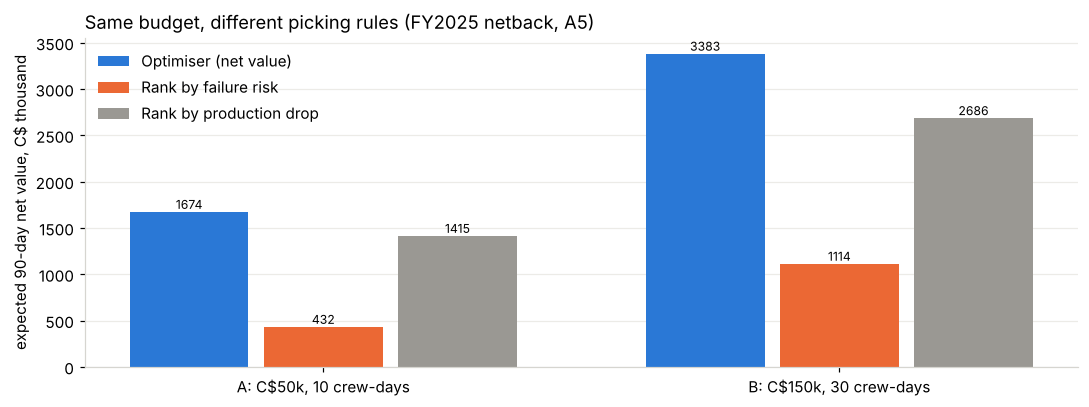

,well_id,job_type,field_operating_area,oil_lost_per_day,failure_risk,expected_extra_oil,repeat_failure_rate,repair_cost_cad,crew_days,net_value_cad,flag_reason
66,106150503728W300,Corod Rod Repair,Cosine,9.02,0.34,691.9,0.65,6023.0,0.35,184503.73,Output 82% below own baseline (9.0 m3/d); 4 fa...
37,142133003327W300,Corod Rod Repair,Court,7.47,0.42,605.2,0.48,6023.0,0.35,160629.38,"High 30-day failure risk (42%, rank 38); Outpu..."
53,108063404125W300,Stick Rod Repair,Winter,8.24,0.38,590.4,0.75,2474.0,0.23,160102.94,Output 75% below own baseline (8.2 m3/d); 4 fa...
535,101110403520W300,Stick Rod Repair,Druid Main,7.68,0.10,589.8,0.70,2474.0,0.23,159937.72,Output 87% below own baseline (7.7 m3/d); rod ...
541,106110403520W300,Stick Rod Repair,Druid Main,6.09,0.10,438.0,0.70,2474.0,0.23,118136.94,Output 63% below own baseline (6.1 m3/d); rod ...
493,106102003420W300,Stick Rod Repair,Druid Main,6.78,0.11,421.8,0.70,2474.0,0.23,113675.99,Output 40% below own baseline (6.8 m3/d); rod ...
362,105110403520W300,Stick Rod Repair,Druid Main,5.49,0.14,341.2,0.70,2474.0,0.23,91481.37,Output 41% below own baseline (5.5 m3/d); rod ...
216,191113103327W300,Stick Rod Repair,Court,3.78,0.20,311.1,0.53,2474.0,0.23,83192.81,Output 88% below own baseline (3.8 m3/d)
28,131033603528W300,Stick Rod Repair,Cactus Lake,3.91,0.46,284.5,0.61,2474.0,0.23,75868.04,"High 30-day failure risk (46%, rank 29); Outpu..."
0,101121104225W300,Stick Rod Repair,Winter,3.54,0.76,266.9,0.75,2474.0,0.23,71021.57,"High 30-day failure risk (76%, rank 1); Output..."


In [19]:
fig, ax = plt.subplots(figsize=(10, 3.8)); rules = R.rule.unique(); cols = [BLUE, ORANGE, GRAY]
for k, (rule, c_) in enumerate(zip(rules, cols)):
    v = R[R.rule == rule].net_value_cad.values / 1e3
    b = ax.bar(np.arange(2) + (k - 1) * .26, v, .23, color=c_, label=rule); ax.bar_label(b, fmt="%.0f", fontsize=8)
ax.set_xticks(range(2), list(SCEN)); ax.set_ylabel("expected 90-day net value, C$ thousand"); ax.legend(frameon=False)
ax.set_title("Same budget, different picking rules (FY2025 netback, A5)"); ax.grid(axis="x", visible=False); save(fig, "11_budget_scenarios")
sel = picks[("A: C$50k, 10 crew-days", "Optimiser (net value)")]
sel[["well_id", "job_type", "field_operating_area", "oil_lost_per_day", "failure_risk", "expected_extra_oil", "repeat_failure_rate",
     "repair_cost_cad", "crew_days", "net_value_cad", "flag_reason"]].sort_values("net_value_cad", ascending=False).round(2)

## Caveats
1. **Failure definition.** Before mid-2025 there is no failure log, so a failure means a failure-driven repair job. The model predicts failures that crews actually responded to.
2. **Company-wide prices (A1).** Netbacks are company-wide, and they include thermal bitumen. Lloydminster heavy oil may realize less per barrel, so treat the dollar values as approximate and check the sensitivity with the FY2025 vs Q3 2026 rows.
3. **Counterfactual.** "Waiting" means the well stays in its failed state for 90 days. That is right for a parted rod string, but it overstates the value for wells that are only slightly degraded.
4. **Assumed costs.** Costs are field estimates (A3) and crew-days are job durations (A4). Business's `repair_inputs.csv` replaces the stand-in file when it is ready.
5. **Production drop alone barely beats random** at predicting failures. Most of the signal comes from recent downtime and failure history.